# E-Commerce Infrastructure Scaling Intelligence 

**Author:**Niharika N K

## Objective

The objective of this analysis is to evaluate the rediness of NimbusCart's infrastructure for future demand surges by :

1. Forcasting next 15-min request volume
2. Predicting wheather proactive scale-up actions are required 
3. Discovering operational infrastructure states using clustering 
4. Providing actionable recommendations for SRE teams.

# Task 1 : Data Understanding and Validation
## Purpose 
Before building ML Models , the set must be validated to understand its structure , quality , completeness and operational characteristics

### Key Questions 

- What is the size of the dataset ?
- What time period does it cover ?
- Are there missing values ?
- Are there unusual observations ?
- Are the target variables balanced ?

In [30]:
## 1.1 Dataset Structure

#This section provides an overview of the dataset structure, including the number of rows and columns, data types, and a brief description of the data.

import pandas as pd 
import numpy as np

scaling_log = pd.read_csv(r"D:\Projects\ecommerce-infrastructure-scaling\data\ecommerce_infrastructure_scaling (2).csv")
print(f"Scaling Log DataFrame Shape: {scaling_log.shape}")
print(f"Scaling Log DataFrame Columns: {scaling_log.columns.tolist()}")
print(f"Scaling Log DataFrame Info for data types:\n{scaling_log.info()}")

print(f"Scaling Log DataFrame Head:\n{scaling_log.head()}")
#handling the timestamp column
scaling_log['timestamp'] = pd.to_datetime(scaling_log['timestamp'], errors='coerce')
print(f"Scaling Log DataFrame Info for data types:\n{scaling_log.info()}")


Scaling Log DataFrame Shape: (3023, 14)
Scaling Log DataFrame Columns: ['timestamp', 'sale_event', 'region', 'active_users', 'requests_per_min', 'orders_per_min', 'cpu_utilization', 'memory_utilization', 'network_mbps', 'disk_utilization', 'response_time_ms', 'current_capacity_rpm', 'next_15min_requests', 'scale_up_required']
<class 'pandas.DataFrame'>
RangeIndex: 3023 entries, 0 to 3022
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   timestamp             3023 non-null   str    
 1   sale_event            3023 non-null   str    
 2   region                3022 non-null   str    
 3   active_users          3023 non-null   int64  
 4   requests_per_min      3023 non-null   int64  
 5   orders_per_min        3023 non-null   int64  
 6   cpu_utilization       3023 non-null   float64
 7   memory_utilization    3021 non-null   float64
 8   network_mbps          3022 non-null   float64
 9   disk_utili

In [31]:
## 1.2 Time coverage Analysis 

# Data is time-dependent
#Understanding the start and end dates ensures that later model traning uses a chronological rather than random order 

print(f"Scaling log DataFrame latest timestamp: {scaling_log['timestamp'].max()}")
print(f"Scaling log DataFrame earliest timestamp: {scaling_log['timestamp'].min()}")

Scaling log DataFrame latest timestamp: 2026-07-21 23:40:00
Scaling log DataFrame earliest timestamp: 2026-07-01 00:00:00


In [32]:
## 1.3 Sale Event Distribution Analysis and Region count distribution

# to check the distribution of events over each events

print(f"Scaling log DataFrame unique sale events: {scaling_log['sale_event'].unique()}")
print(f"Scaling log DataFrame sale event counts:\n{scaling_log['sale_event'].value_counts()}")
print(f"Scaling log DataFrame unique regions: {scaling_log['region'].value_counts()}")

Scaling log DataFrame unique sale events: <StringArray>
['Normal', 'Sale', 'Flash Sale']
Length: 3, dtype: str
Scaling log DataFrame sale event counts:
sale_event
Normal        1583
Sale          1332
Flash Sale     108
Name: count, dtype: int64
Scaling log DataFrame unique regions: region
South    1008
North    1007
West     1007
Name: count, dtype: int64


#Summary statistics and Target analysis
## 1.6 Target Variable analysis 

it has two targets 
regression target : next_15min_requests

Classification target : scale_up_required

In [33]:
print(f"Scaling Log DataFrame Description:\n{scaling_log.describe()}")

Scaling Log DataFrame Description:
                 timestamp  active_users  requests_per_min  orders_per_min  \
count                 3023   3023.000000       3023.000000     3023.000000   
mean   2026-07-11 11:50:00   1337.548131       1672.141250       33.506120   
min    2026-07-01 00:00:00    214.000000        317.000000        2.000000   
25%    2026-07-06 05:55:00    722.000000        907.500000       13.000000   
50%    2026-07-11 11:50:00   1051.000000       1310.000000       22.000000   
75%    2026-07-16 17:45:00   1866.500000       2339.000000       50.000000   
max    2026-07-21 23:40:00   5836.000000       7272.000000      199.000000   
std                    NaN    878.556405       1097.354111       29.266681   

       cpu_utilization  memory_utilization  network_mbps  disk_utilization  \
count      3023.000000         3021.000000   3022.000000       3022.000000   
mean         78.017168           67.222344    551.604269         58.358570   
min          28.900000      

In [34]:
print(
    f"Scaling log classification target distribution:\n"
    f"{scaling_log['scale_up_required'].value_counts(normalize=True)}\n"
    f"Percentage of scale-up required Target: {(scaling_log['scale_up_required'].value_counts(normalize=True) * 100).round(2)}%\n"
    f"Regression target summary:\n{scaling_log['next_15min_requests'].describe()}"
)

Scaling log classification target distribution:
scale_up_required
0    0.736355
1    0.263645
Name: proportion, dtype: float64
Percentage of scale-up required Target: scale_up_required
0    73.64
1    26.36
Name: proportion, dtype: float64%
Regression target summary:
count    3023.000000
mean     1672.539199
std      1095.676063
min       327.000000
25%       907.500000
50%      1309.000000
75%      2333.000000
max      7248.000000
Name: next_15min_requests, dtype: float64


### EDA Findings — Server Capacity Scaling

**1. Distribution of numerical features**

For several numerical features, the mean is greater than the median, suggesting potential right-skewness. The substantial gap between the 75th percentile and maximum values in some features may indicate occasional high-load observations. These could represent traffic spikes or periods of increased resource demand and should be investigated to determine whether they reflect legitimate server activity or anomalous behavior.

**2. Classification target — Scaling Required**

The classification target is imbalanced, with the `Scale Up` class accounting for approximately 26% of observations. This indicates that scaling-required events occur less frequently than the other class or classes. Model evaluation should therefore consider precision, recall, F1-score, and the confusion matrix rather than relying solely on accuracy.

**3. Regression target — Requests in the Next 15 Minutes**

The distribution of the next-15-minute request count should be examined separately to understand its central tendency, variability, skewness, and potential traffic spikes. If the target is right-skewed, prediction errors during high-demand periods may be particularly important to evaluate, as underestimating future traffic could affect capacity planning.

**4. Implications for capacity planning**

The observed variation in traffic highlights the importance of identifying both normal operating conditions and sudden increases in demand. The classification model can predict whether scaling is required, while the regression model can estimate future request volume to support proactive capacity planning.


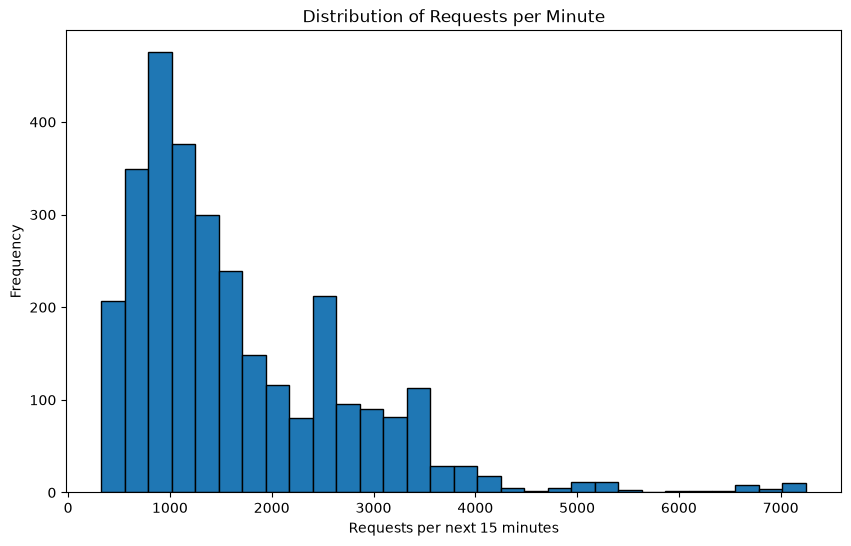

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(scaling_log['next_15min_requests'], bins=30, edgecolor='black')
plt.xlabel('Requests per next 15 minutes')
plt.ylabel('Frequency')
plt.title('Distribution of Requests per Minute')
plt.savefig('D:\\Projects\\ecommerce-infrastructure-scaling\\outputs\\tasks1\\distribution_of_requests_per_minute.png')  # Save the figure as a PNG file
plt.show()

In [2]:
## 1.4 Missing Values Analysis
# to avoid missing values affecting the model quality.

print(f"Scaling log DataFrame missing values:\n{scaling_log.isnull().sum()}")

for col in scaling_log.columns:
    missing_percentage = scaling_log[col].isnull().mean() * 100
    if missing_percentage > 0:
     print(f"Column '{col}' has {missing_percentage:.2f}% missing values.")
     #check the rows with missing values and its associated sale event.
    print(f"Only a small number of missing values were identified in : region , memory utilization and network_mbps and disk_utilization")
    print(f"To handle since its very few , we shall verify which sale events its triggering ")
    if scaling_log[col].isnull().any():
       missing_rows = scaling_log[scaling_log[col].isnull()]
       print(f"Rows with missing values in column '{col}':\n{missing_rows[['sale_event', col]]}\n")


        

NameError: name 'scaling_log' is not defined

## 1.5 Unusual and Extreme Observations

Infrastructure telematry often contains legitatmate spikes caused by real operational events 

Outliers needs to be checked rather than to remove 



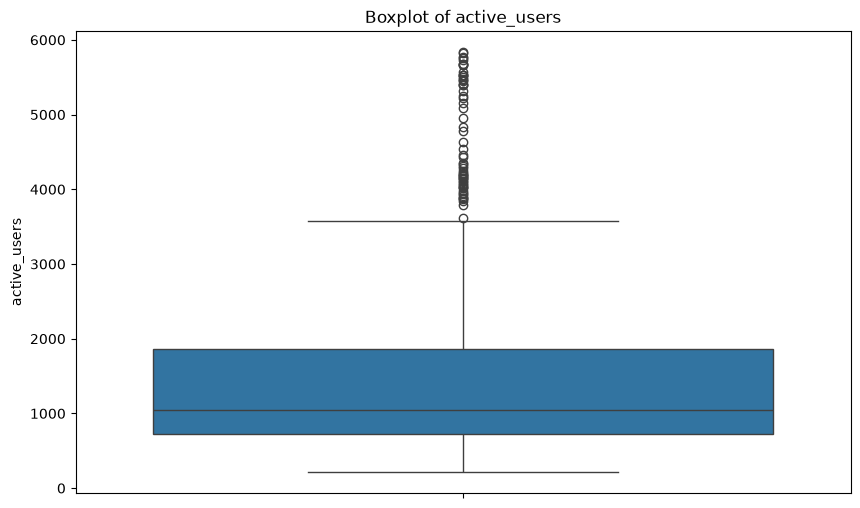

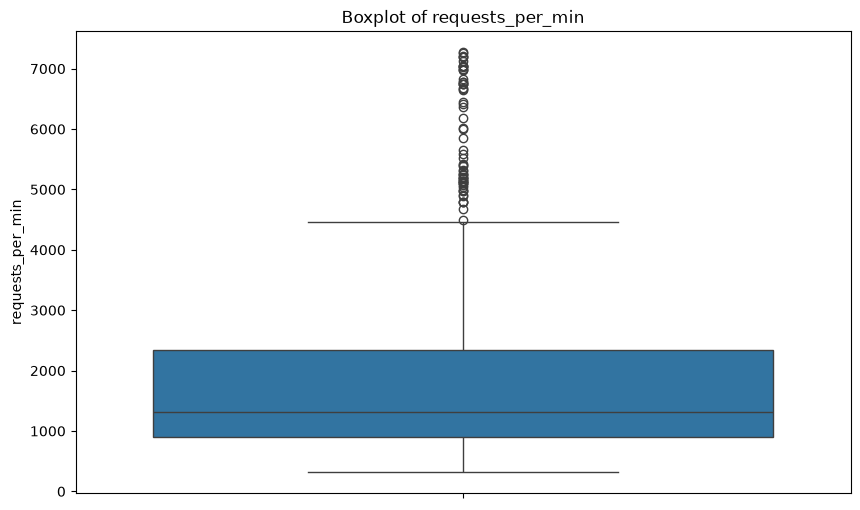

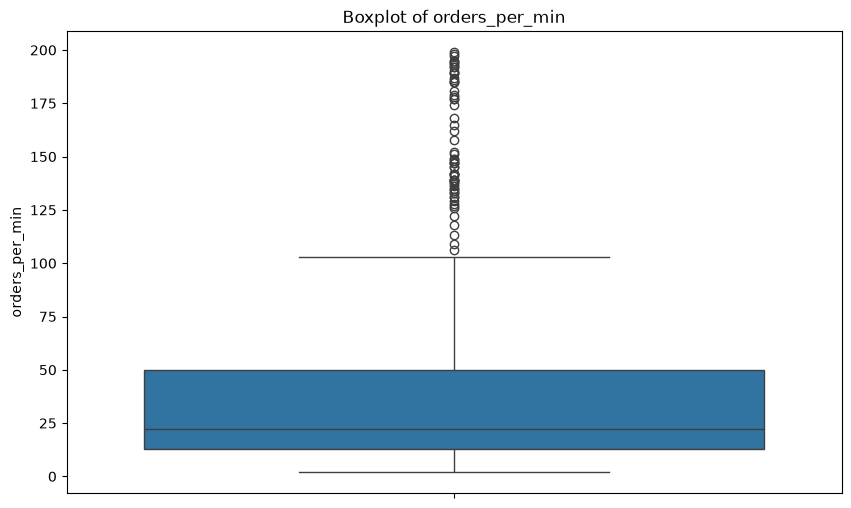

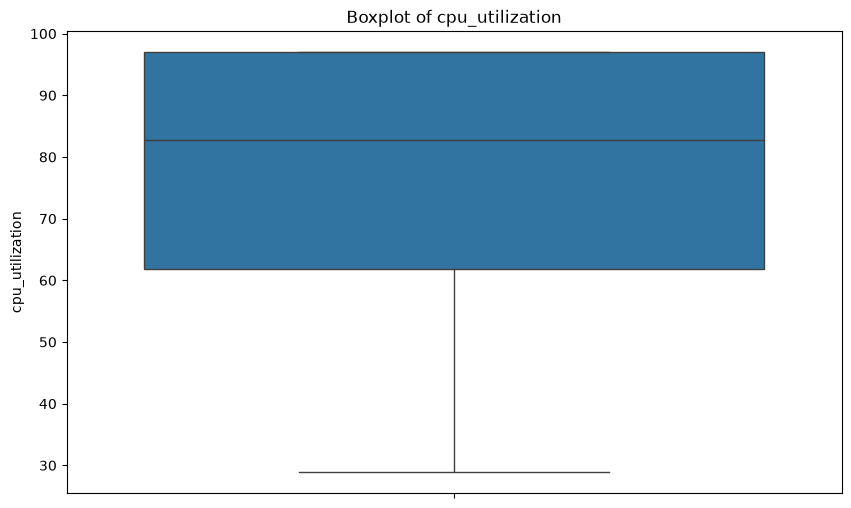

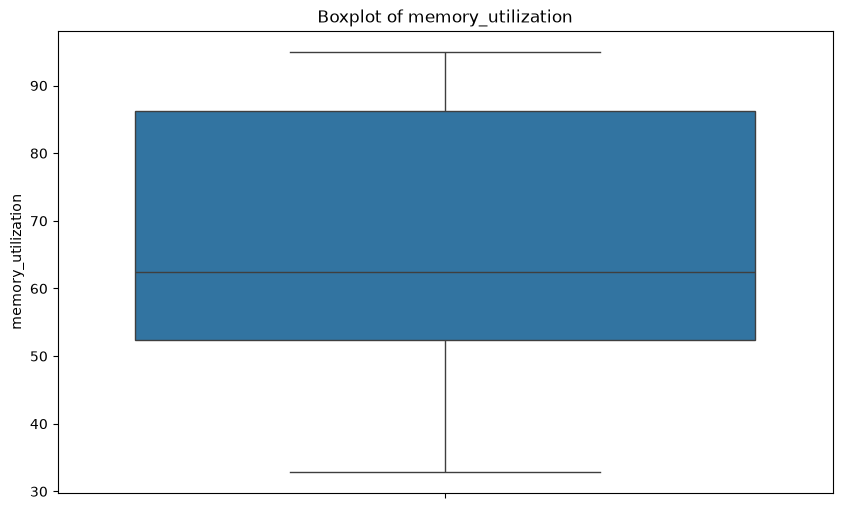

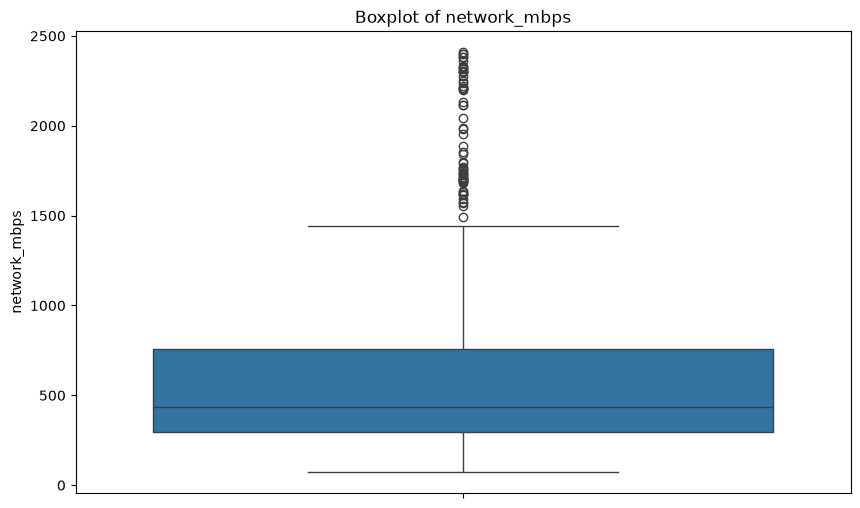

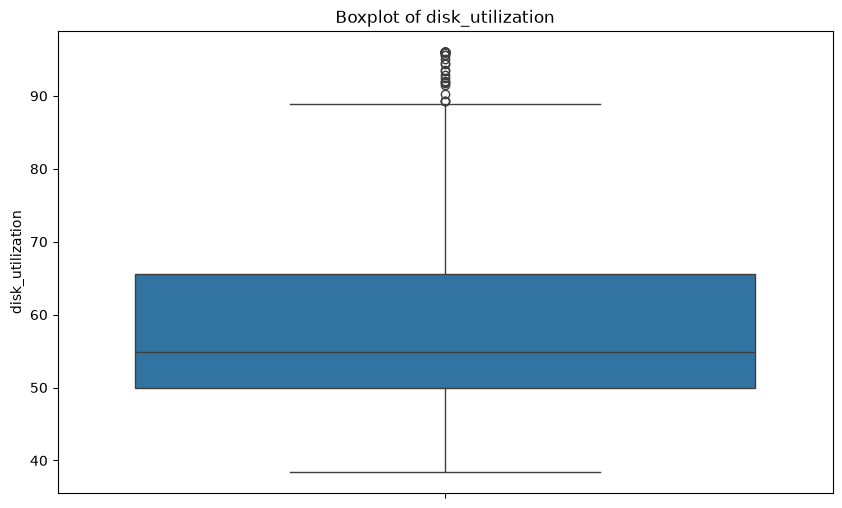

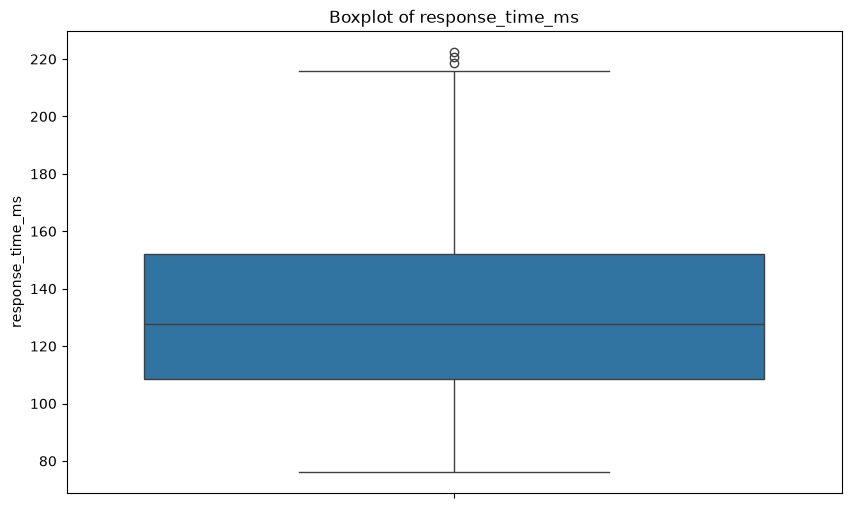

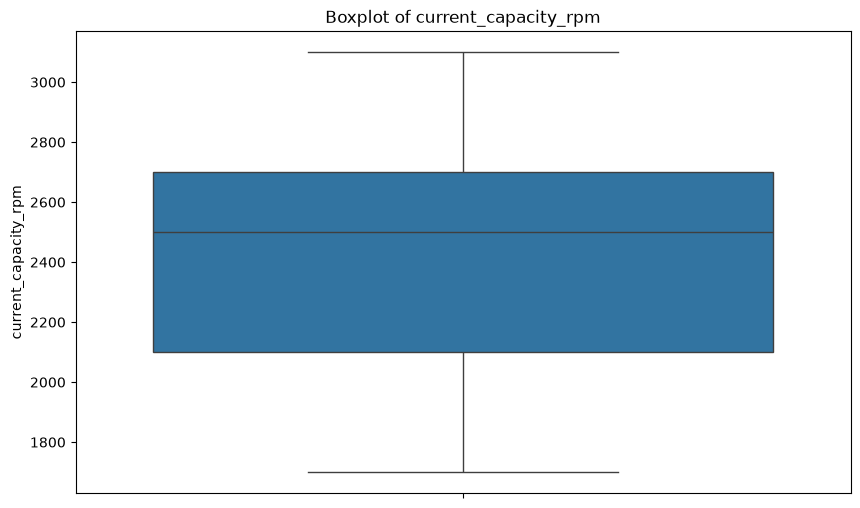

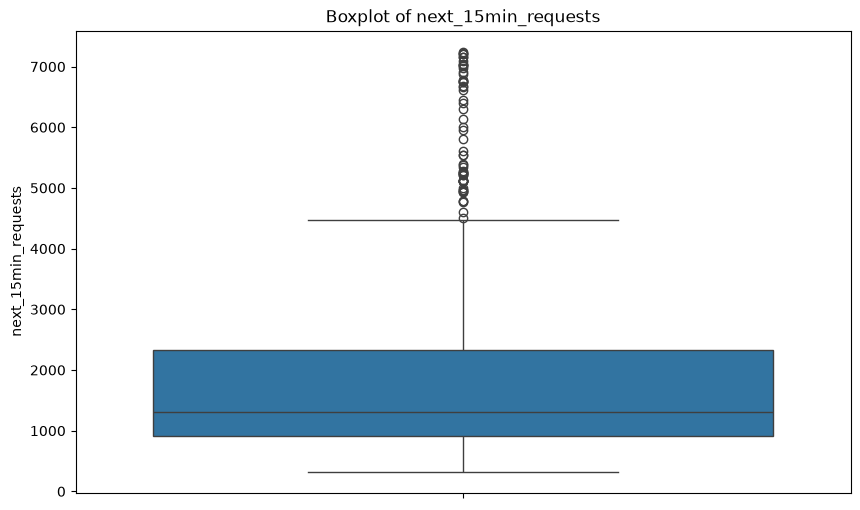

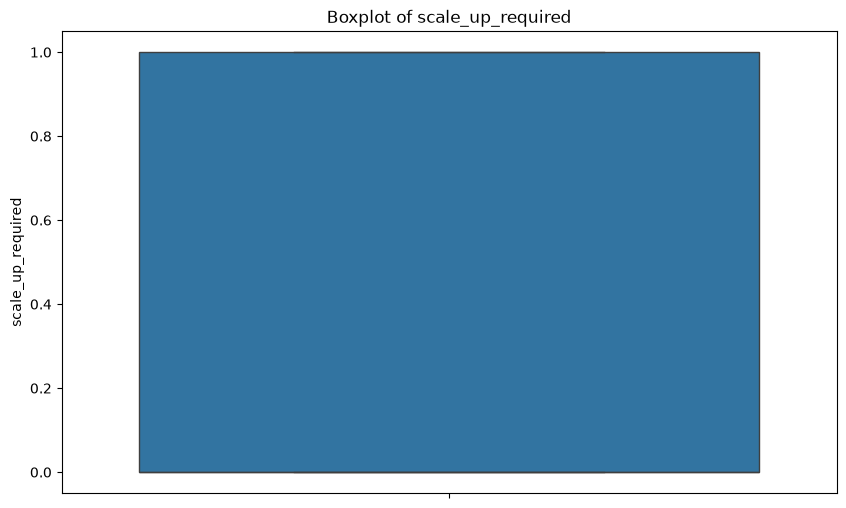

In [37]:
import seaborn as sns

for col in scaling_log.columns:
    if scaling_log[col].dtype in [np.float64, np.int64]:
        plt.figure(figsize=(10, 6))
        sns.boxplot(scaling_log[col])
        plt.title(f'Boxplot of {col}')
        plt.savefig(f'D:\\Projects\\ecommerce-infrastructure-scaling\\outputs\\tasks1\\boxplot_{col}.png')
        plt.show()
             

In [38]:
# All the EDA completed and data remains intact with no change.


print(f"scaling log dataframe shape {scaling_log.shape}")
print(f"scaling log dataframe info {scaling_log.info()}")

scaling log dataframe shape (3023, 14)
<class 'pandas.DataFrame'>
RangeIndex: 3023 entries, 0 to 3022
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   timestamp             3023 non-null   datetime64[us]
 1   sale_event            3023 non-null   str           
 2   region                3022 non-null   str           
 3   active_users          3023 non-null   int64         
 4   requests_per_min      3023 non-null   int64         
 5   orders_per_min        3023 non-null   int64         
 6   cpu_utilization       3023 non-null   float64       
 7   memory_utilization    3021 non-null   float64       
 8   network_mbps          3022 non-null   float64       
 9   disk_utilization      3022 non-null   float64       
 10  response_time_ms      3023 non-null   float64       
 11  current_capacity_rpm  3023 non-null   int64         
 12  next_15min_requests   3023 non-null   int64     

# Task 2: Data Preparation for ML

## Purpose : Data must be transformed into a machine learning ready dataset 

- create time based features 
- handle missing values
- Encode categorical variables 
- Apply scaling where appropriate 
- seperate target from predictors

The objective is to ensure a clean and reproducible preprocessing pipeline before model developement.


In [39]:
#craeting a copy of df
scaling_log_ml = scaling_log.copy()

#Timestamp information was decomposed into hour of day, day of week and is_weekend features to help the model learn the temporal patterns in the data.

scaling_log_ml['timestamp'] = pd.to_datetime(scaling_log_ml['timestamp'], errors='coerce')

scaling_log_ml['hour_of_day'] = scaling_log_ml['timestamp'].dt.hour
scaling_log_ml['day_of_week'] = scaling_log_ml['timestamp'].dt.dayofweek

scaling_log_ml['is_weekend'] = ( scaling_log_ml['day_of_week'] >= 5).astype(int)


In [3]:
#Missing value treatment

for col in scaling_log_ml.columns:
    if (scaling_log_ml[col].isnull().any()) and pd.api.types.is_numeric_dtype(scaling_log_ml[col]):
        
        print(f"Missing values before dropping {col}:\n{scaling_log_ml[col].isnull().sum()}")
        
        scaling_log_ml[col] = scaling_log_ml[col].fillna(scaling_log_ml[col].median())

        print(f"Missing values after filling {col}:\n{scaling_log_ml[col].isnull().sum()}")
    elif (scaling_log_ml[col].isnull().any()) and pd.api.types.is_string_dtype(scaling_log_ml[col]):
        print(f"Missing values before dropping {col}:\n{scaling_log_ml[col].isnull().sum()}")
        
        scaling_log_ml[col] = scaling_log_ml[col].fillna(scaling_log_ml[col].mode()[0])

        print(f"Missing values after filling {col}:\n{scaling_log_ml[col].isnull().sum()}")
        

NameError: name 'scaling_log_ml' is not defined

# Why Median to handle missing values

because we had minimal missing values but since its infrastructure metrics and exibits skewed distribution, the median is less sensitive to extreme values than the mean.

categorical variables were imputed using the mode to preserve the existing category distribution while minimizing distortion of the dataset


# Encode categories 

In [41]:
categorical_cols = [col for col in scaling_log_ml.columns if scaling_log_ml[col].dtypes == 'str']

print(f"Categorical columns:\n{categorical_cols}")

# one hot encoding for categorical variables, avoid multicollinearity by dropping the first category to avoid the dummy variable trap.

scaling_log_ml = pd.get_dummies(scaling_log_ml, columns=categorical_cols, drop_first=True)
for col in categorical_cols:
    for col in categorical_cols:
        encoded_cols = [c for c in scaling_log_ml.columns if c.startswith(f"{col}_")]
        print(f"Encoded columns for '{col}': {encoded_cols}")
        print(scaling_log_ml[encoded_cols].head())

Categorical columns:
['sale_event', 'region']
Encoded columns for 'sale_event': ['sale_event_Normal', 'sale_event_Sale']
   sale_event_Normal  sale_event_Sale
0               True            False
1               True            False
2               True            False
3               True            False
4               True            False
Encoded columns for 'region': ['region_South', 'region_West']
   region_South  region_West
0         False        False
1          True        False
2         False         True
3         False        False
4          True        False
Encoded columns for 'sale_event': ['sale_event_Normal', 'sale_event_Sale']
   sale_event_Normal  sale_event_Sale
0               True            False
1               True            False
2               True            False
3               True            False
4               True            False
Encoded columns for 'region': ['region_South', 'region_West']
   region_South  region_West
0         False      

# Scaling 

LR is sensitive to feature scaling and will use standerdised inputs during model traning

Tree-based algorithms such as Decision Trees, random Forests , K-Means and DBSCAN do not require scaling for predictive performance

so scaling will be applied only where relevant within the modeling pipeline

# Outlier Review 

In [42]:
outliers_summary = []
for col in scaling_log_ml.columns:
    if scaling_log_ml[col].dtypes in [np.float64,np.int64]:
       Q1 = scaling_log_ml[col].quantile(0.25)

       Q3 = scaling_log_ml[col].quantile(0.75)
  
       IQR = Q3 - Q1
       Upper_bound = Q3 + 1.5 * IQR
       Lower_bound = Q1 - 1.5 * IQR

       max = scaling_log_ml[col].max()
       
       outliers = scaling_log_ml[
                       (scaling_log_ml[col] < Lower_bound) |
                       (scaling_log_ml[col] > Upper_bound)
       ].shape[0]
      
       outliers_summary.append((Q1, Q3, IQR,col, outliers,max))

       pd.DataFrame(
           outliers_summary, columns=['Q1', 'Q3', 'IQR', 'Column', 'Outlier Count','max']
       )

print(f"Outlier summary:\n{pd.DataFrame(outliers_summary, columns=['Q1', 'Q3', 'IQR', 'Column', 'Outlier Count','max'])}")

Outlier summary:
         Q1       Q3      IQR                Column  Outlier Count     max
0    722.00  1866.50  1144.50          active_users             62  5836.0
1    907.50  2339.00  1431.50      requests_per_min             62  7272.0
2     13.00    50.00    37.00        orders_per_min             68   199.0
3     61.85    97.00    35.15       cpu_utilization              0    97.0
4     52.45    86.30    33.85    memory_utilization              0    95.0
5    295.30   758.40   463.10          network_mbps             62  2409.7
6     49.90    65.55    15.65      disk_utilization             65    96.0
7    108.40   152.20    43.80      response_time_ms              3   222.4
8   2100.00  2700.00   600.00  current_capacity_rpm              0  3100.0
9    907.50  2333.00  1425.50   next_15min_requests             61  7248.0
10     0.00     1.00     1.00     scale_up_required              0     1.0
11     0.00     1.00     1.00            is_weekend              0     1.0


The requests per min contains observations considerably above the upper quartile 
75th percentle : 2339 req/min
max : 7272 req/min

this dataset includes normal, sale and flash sale periods 

In a e commerce env large spikes in requests users and network throughtput are expected during promotional events 

therefore these observations were reviewed as potential ops surges rather than automatically trated as outliers

# Seperate targets 

In [43]:
y_reg = scaling_log_ml['next_15min_requests']

y_cls = scaling_log_ml['scale_up_required']

X = scaling_log_ml.drop(columns=['next_15min_requests', 'scale_up_required'])

# Task 3: Feature Engineering ans Selection 

## Purpose 

Raw infrastructure metrics provide valuable information , but additional buisness-oriented features can improve predictive performance 

This section creates new features that better represent demand pressure, infrastructure stress, and remaining capacity while ensuring that no target leakage is introduced

The resulting feature set will be used for both regression and classification tasks.

In [44]:
# Capacity headroom 

#Represents the no of requests per min that can still be accomadated before current capacity is exhausted 

#Lower values indicate increased infra pressure

scaling_log_ml['capacity_headroom'] = ( scaling_log_ml['current_capacity_rpm'] - scaling_log_ml['requests_per_min'] )


In [45]:
# Demand intensity 

# Represents the average request load generated by each active user.
# Higher values indicate greater presure on the application per user.
scaling_log_ml['demand_intensity'] = ( scaling_log_ml['requests_per_min']/ scaling_log_ml['active_users']  )

In [46]:
#Utilization Pressure

#Represents combined infrastructure utilization across CPU, memory and storage resources 
#Higher values indicate increasing operational stress

scaling_log_ml['Utilization Pressure'] = ( scaling_log_ml['cpu_utilization']+ scaling_log_ml['memory_utilization'] + scaling_log_ml['disk_utilization']  )/3

In [47]:
#Resource Efficiency 

scaling_log_ml['requests_per_cpu'] = ( scaling_log_ml['requests_per_min']/ scaling_log_ml['cpu_utilization'] )

is this feature really usefull to distinguish the target

 capacity_headroom
                          mean  median
scale_up_required                     
0                  1228.148697  1220.0
1                  -671.570891  -426.0

 demand_intensity
                       mean    median
scale_up_required                    
0                  1.253830  1.251293
1                  1.249935  1.249561

 Utilization Pressure
                        mean     median
scale_up_required                      
0                  60.767041  59.916667
1                  87.687829  88.066667

 requests_per_cpu
                        mean     median
scale_up_required                      
0                  15.530324  15.256950
1                  32.265216  30.268041
Findings : Capcity headroom showed strong seperation between scale-up and non scale up , inclusing negative values for in some cases while scaling up indicating cuurent request exeeds available infrastructure
similarly utilization Pre

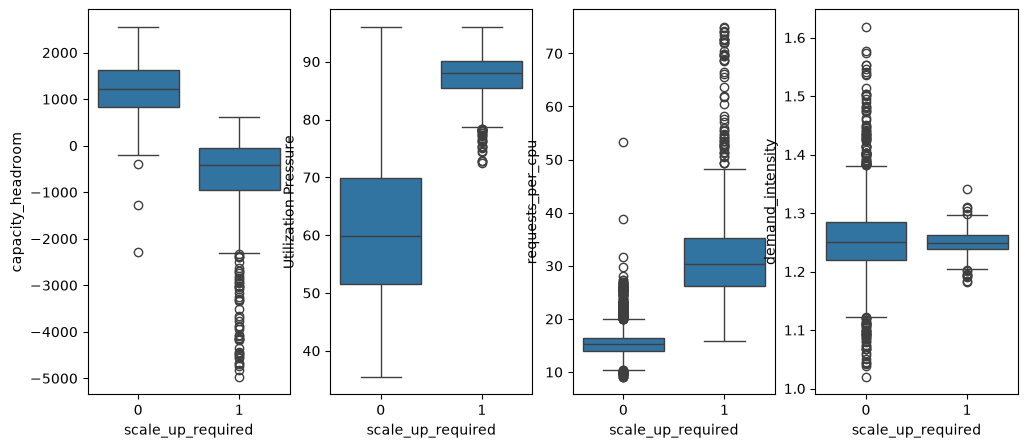

In [48]:
#Verify new features 

scaling_log_ml[
[
 'capacity_headroom',
 'demand_intensity',
 'Utilization Pressure',
 'requests_per_cpu'
]
].head()


new_features = [
 'capacity_headroom',
 'demand_intensity',
 'Utilization Pressure',
 'requests_per_cpu'
]

print("is this feature really usefull to distinguish the target")



for col in new_features:
  print("\n",col)
  print(scaling_log_ml.groupby('scale_up_required')[col].agg(['mean','median']))
  

print("Findings : Capcity headroom showed strong seperation between scale-up and non scale up , inclusing negative values for in some cases while scaling up indicating cuurent request exeeds available infrastructure")
print("similarly utilization Pressure and CPU requests indicating likely valuable predictive feature")
print("But Demand intensity alone may not strong influence scaling decisions with identical mean values in both class, but feature is retained for evaluation during traning")

fig, ax = plt.subplots(1,4,figsize=(12,5))
sns.boxplot(
    data= scaling_log_ml,
    x = 'scale_up_required',
    y = 'capacity_headroom',
    ax = ax[0]
  )
sns.boxplot(
    data = scaling_log_ml,
    x= 'scale_up_required',
    y= 'Utilization Pressure',
    ax= ax[1]
  )
sns.boxplot(
    data = scaling_log_ml,
    x= 'scale_up_required',
    y= 'requests_per_cpu',
    ax= ax[2]
  )
sns.boxplot(
    data = scaling_log_ml,
    x= 'scale_up_required',
    y= 'demand_intensity',
    ax= ax[3]
  )

plt.savefig(r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks3\Feature_selection.png")




# Correlation Analysis 

To understand relationships between infrastructure metrics and target variable 
To determine which features may provide predictive value during model developement


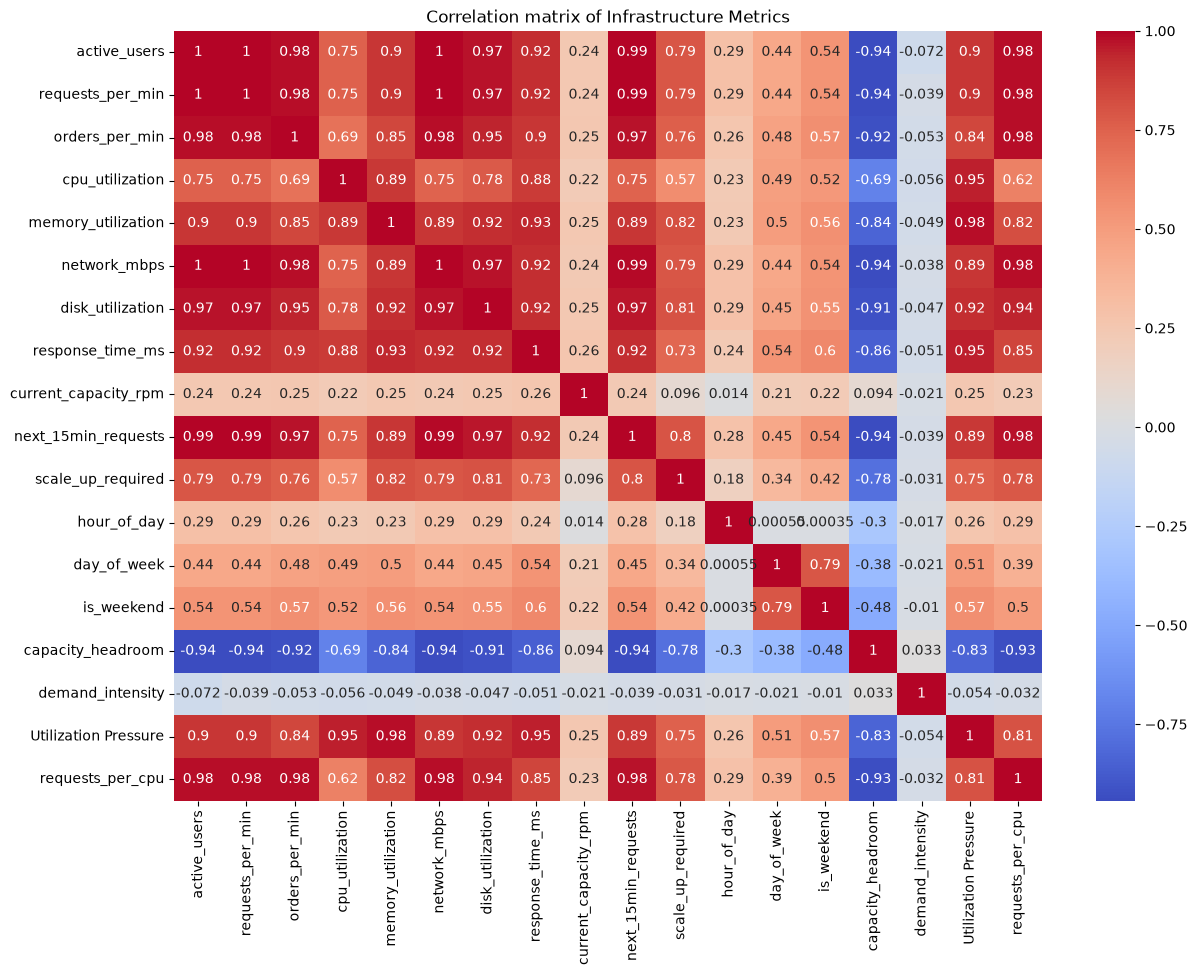

In [49]:
corre_matrix = (
    scaling_log_ml.select_dtypes(include='number').corr()
     )

plt.figure(figsize=(14,10))

sns.heatmap(
    data = corre_matrix,
    cmap="coolwarm",
    annot= True,
    fmt=".2g"
)

plt.title(
    "Correlation matrix of Infrastructure Metrics")

plt.savefig(
   r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks3\correlation_heatmap.png"

)

plt.show()

In [50]:
#Regression Target
print(f"Regression target correlation: {corre_matrix['next_15min_requests'].sort_values(
    ascending=False
)}")

print(f"Classification target correlation: {corre_matrix['scale_up_required'].sort_values(
    ascending=False
)}")

Regression target correlation: next_15min_requests     1.000000
requests_per_min        0.993517
active_users            0.992677
network_mbps            0.992184
requests_per_cpu        0.975780
orders_per_min          0.973838
disk_utilization        0.968104
response_time_ms        0.916586
memory_utilization      0.894240
Utilization Pressure    0.893394
scale_up_required       0.800472
cpu_utilization         0.748639
is_weekend              0.543086
day_of_week             0.445190
hour_of_day             0.284335
current_capacity_rpm    0.237799
demand_intensity       -0.038678
capacity_headroom      -0.937956
Name: next_15min_requests, dtype: float64
Classification target correlation: scale_up_required       1.000000
memory_utilization      0.815412
disk_utilization        0.809238
next_15min_requests     0.800472
requests_per_min        0.794753
active_users            0.794434
network_mbps            0.794376
requests_per_cpu        0.782854
orders_per_min          0.761286
U


Current request volume, active user count and order volume exhibit strong positive relationships with future request demand

This suggests that workload-related metrics are likely to be strong predictors for forecastin future traffic

Scale-up requiremnts show positive correlation with utilization pressure and negative correlation with capacity headroom

In [51]:
# Regression Dataset 

X_reg = scaling_log_ml.drop(
    columns= ['next_15min_requests',
    'scale_up_required',
    'timestamp']
)

print("Regression features")
print(X_reg.columns.tolist())
#next_15min_requests is target , scale_up_required is removed because it represents a future operational 
#outcome and would leak information into the forecasting model

Regression features
['active_users', 'requests_per_min', 'orders_per_min', 'cpu_utilization', 'memory_utilization', 'network_mbps', 'disk_utilization', 'response_time_ms', 'current_capacity_rpm', 'hour_of_day', 'day_of_week', 'is_weekend', 'sale_event_Normal', 'sale_event_Sale', 'region_South', 'region_West', 'capacity_headroom', 'demand_intensity', 'Utilization Pressure', 'requests_per_cpu']


In [100]:
#Regression Dataset 

X_cls = scaling_log_ml.drop(
    columns= [
       'scale_up_required',
       'next_15min_requests',
       'timestamp'
    ]
)
print("Classification features")
print(X_cls.columns.tolist())
#next_15min_requests is future demand and would not be available when making real-time scaling decision

Classification features
['active_users', 'requests_per_min', 'orders_per_min', 'cpu_utilization', 'memory_utilization', 'network_mbps', 'disk_utilization', 'response_time_ms', 'current_capacity_rpm', 'hour_of_day', 'day_of_week', 'is_weekend', 'sale_event_Normal', 'sale_event_Sale', 'region_South', 'region_West', 'capacity_headroom', 'demand_intensity', 'Utilization Pressure', 'requests_per_cpu']


# Task 4 : Demand Forecasting (Regression)

## Buisness Objective 

Infrastructure teams need early visibility into future demand so that scaling decisions can be made proactively rather than reactively.

The objective of this task is to predict the expected request volume for the next 15 min using current infrastructure and workload telemetry.

Target variable :

- Linear Regression 
- Random Forest Regressor 

Eval Metrics :

- MAE
- RMSE

In [86]:
#dataset preparation 
## Chronological data split 

#Random shuffeling is avoided because infrastructure telemetry is time-dependent 

#The first 80% of records were used for traning while the final 20% were reserved for testing , preserving the real world sequesnce of events

split_index = int(len(X_reg)*0.8)

X_train = X_reg[:split_index]
X_test = X_reg[split_index:]
Y_train = y_reg[:split_index]
Y_test = y_reg[split_index:]

In [87]:
from sklearn.preprocessing import StandardScaler

scalar = StandardScaler()

X_train_scaled = scalar.fit_transform(X_train)
X_test_scaled = scalar.transform(X_test)


In [88]:
#Train the data and predict test data
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train_scaled,Y_train)

lr_pred = lr.predict(X_test_scaled)

In [89]:
#Evaluation
from sklearn.metrics import mean_absolute_error,mean_squared_error,mean_absolute_percentage_error
import numpy as np

lr_MAE = mean_absolute_error(Y_test,lr_pred)

lr_RMSE = np.sqrt(
    mean_squared_error(Y_test,lr_pred)
)

lr_MAPE = mean_absolute_percentage_error(
    Y_test,
    lr_pred
)

print("MAE:",lr_MAE)
print("RMSE:",lr_RMSE)
print("MAPE:",lr_MAPE)


MAE: 64.8004754274893
RMSE: 191.50404265671494
MAPE: 0.022980205356006575


In [90]:
df_original = scaling_log.copy()
results = pd.DataFrame()
results['actual'] = Y_test
results['predicted'] = lr_pred
results['error'] = abs(Y_test-lr_pred)
results['sale event'] = (
    df_original.iloc[split_index:]
    ['sale_event'].values
)

results.groupby(
    'sale event'
)['error'].mean()


sale event
Flash Sale    176.445411
Normal         25.816461
Sale           68.451875
Name: error, dtype: float64

# Trying Random Forest Regressor 

In [91]:
#Train the data and predict test data
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train_scaled,Y_train)

pred_rf = rf.predict(X_test_scaled)



In [93]:
#evaluation
rf_mae = mean_absolute_error(pred_rf,Y_test)

rf_rmse = np.sqrt(mean_squared_error(
    pred_rf,Y_test
))

rf_mape = mean_absolute_percentage_error(
    Y_test,pred_rf
)

print("MAE:",rf_mae)
print("RMSE:",rf_rmse)


MAE: 194.46747107438017
RMSE: 439.3002919275189


In [94]:
results = pd.DataFrame(
    {'Model':['Linear Regression','Random Forest'],
    'MAE': [lr_MAE,rf_mae],
    'RMSE':[lr_RMSE,rf_rmse]}
)

results

,Model,MAE,RMSE
0,Linear Regression,64.800475,191.504043
1,Random Forest,194.467471,439.300292


In [95]:
df_original = scaling_log.copy()
results = pd.DataFrame()
results['actual'] = Y_test
results['predicted'] = pred_rf
results['error'] = abs(Y_test-lr_pred)
results['sale event'] = (
    df_original.iloc[split_index:]
    ['sale_event'].values
)

results.groupby(
    'sale event'
)['error'].mean()


sale event
Flash Sale    176.445411
Normal         25.816461
Sale           68.451875
Name: error, dtype: float64

## Error Analysis 

# prediction errors differ accross operating conditions

The model performs well during Normal traffic periods, with relatively low forecasting error 

Forecasting accuracy decreases during Sale periods and the largest errors occur during flash Sale conditions

This suggestd that sudden demand spikes are more difficult to predict 

Despite these limitations, the model continues to identify elevated demand conditions and can provide useful early signals for infra planning

The forcasts should therefore be treated as descion-support inputs rather than exact workload estimates, particulaly during promotional events

Both Linear Regression and Random Forest were evaluated using MAE , RMSE and MAPE.

However, Linear Regression achived lower MAE and RMSE values, indicating that its predictions are closer to the actual demand values and that it produces fewer large forecasting errors.

The model also achived a MAPE of 2.2%, meaning that forecasts differ from actual demand by approximatly 2.2% on average

But still fails with sudden demand spikes are more difficult to predict

# The superior performance of Linear Regression suggetss that future demand is largely explained by current workload indicators and does not require highly non-linear decision boundaries for accurate forecasting.


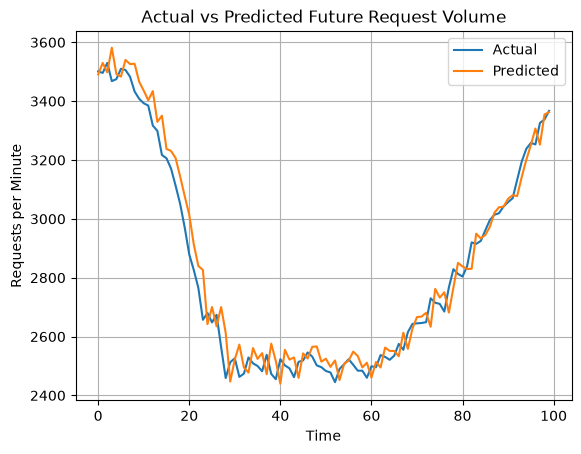

<Figure size 640x480 with 0 Axes>

In [96]:
plt.Figure(figsize=(20,14))

plt.plot(
    Y_test.values[:100],
    label = 'Actual'
)

plt.plot(
    lr_pred[:100],
    label = 'Predicted'
)

plt.legend()

plt.xlabel("Time")
plt.ylabel("Requests per Minute")
plt.title("Actual vs Predicted Future Request Volume")
plt.legend()
plt.grid(True)
plt.show()

plt.savefig(
    r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks4\actual_vs_predicted.png",bbox_inches = "tight"
)



# Is it Useful ?

Despite reduced accuracy during flash sale , the model consistently identifies elevated demand conditions and follows overal workload trends

the model can therefore support proactive capacity planning during typical operations, although additional safeguards or specialised forecasting approaches may be required during major promotional events.

# Task 5

Predict whether Proactive Scale-Up Is Required (Classification)

## Buisness objective

The goal is to predict wheather infrastructure scaling actions should be taken 
proactively based on the current operational state 

Target variable 

- scale_up_required

Models Evaluated

- Decision Tree Classifier
- Random Forest Classifeir

Evaluation metrics 

-Accuracy
-Precision
-Recall
- F1 score 
- Confusion matrix



In [98]:
X_train_cls = X_cls[:split_index]
X_test_cls = X_cls[split_index:]

Y_train_cls = y_cls[ : split_index]
Y_test_cls = y_cls[split_index: ]

X_train_scaled_cls =  scalar.fit_transform(X_train_cls)
X_test_scaled_cls = scalar.transform(X_test_cls)



In [107]:
from sklearn.tree import DecisionTreeClassifier

dt_cls = DecisionTreeClassifier(
    random_state=42
) 

dt_cls.fit(X_train_cls,Y_train_cls)

dt_pred = dt_cls.predict(X_test_cls)


In [116]:
from sklearn.ensemble import RandomForestClassifier

rf_cls =  RandomForestClassifier(
    n_estimators= 100,
    random_state=42
)

rf_cls.fit(X_train_scaled_cls,Y_train_cls)

rf_pred = rf_cls.predict(X_test_scaled_cls)



In [112]:
from sklearn.metrics import(

accuracy_score,
precision_score,
recall_score,
f1_score,
confusion_matrix

)

In [113]:
def evaluate(
    test,pred,model    
):

    print(f"\n {model}")

    print(
        f"Accuracy:{accuracy_score(test,pred)}"
    )
    print(
            f"Precision:{precision_score(test,pred)}"
        )
    print(
            f"Recall:{recall_score(test,pred)}"
        )
    print(
        f"F1 Score:{f1_score(test,pred)}"
    )
    

In [117]:
evaluate(Y_test_cls, rf_pred, "Random Forest Classifier")
evaluate(Y_test_cls, dt_pred, "Decision Trees")


 Random Forest Classifier
Accuracy:0.9603305785123967
Precision:0.9799107142857143
Recall:0.9669603524229075
F1 Score:0.9733924611973392

 Decision Trees
Accuracy:0.9487603305785124
Precision:0.9710467706013363
Recall:0.960352422907489
F1 Score:0.9656699889258029


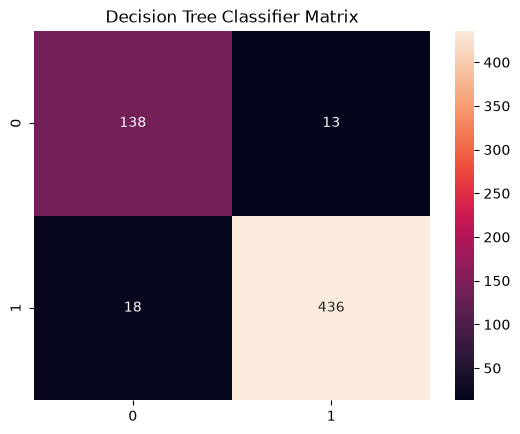

In [121]:
cm_dt = confusion_matrix(
    Y_test_cls,dt_pred
)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d'
)

plt.title(
    "Decision Tree Classifier Matrix"
)
plt.savefig(r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks5\Confusion_matrix_DT.png")
plt.show()

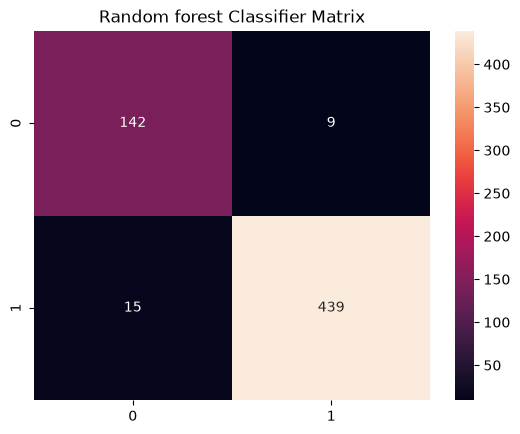

In [122]:
cm_dt = confusion_matrix(
    Y_test_cls,rf_pred
)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d'
)

plt.title(
    "Random forest Classifier Matrix"
)
plt.savefig(r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks5\Confusion_matrix_RF.png")
plt.show()

# Why Recall and Precision have diff operational costs 

Recall measures how many true scale-up events were successfully detected. A missed scale-up event (False negative ) can result in infrastructure saturation, degraded customer experience and potential outages

Precision measures how often a scale-up recommendations is correct. A false Positive results in unnessary infra allocation and increased operational cost, but it does not directly impact reliability

For Nimbuscart, recall is operationally more important because the cost of missing a required scale-up event is generally higher than the cost of an unnecessary scale-up action 

Although both models achived excellent classification performance, Random Forest was selected as the preferred model for proactive scaling decisions

The selection is based on quantitative evidence rather than algorithm complexity

RF achived 

-Higher accuracy ( 96.03% vs 94.88%)
-Higher Precision (97.99% vs 97.10%)
-Higher Recall (96.70% vs 96.04%)
-higher F1 score (97.34% vs 96.57%)

Most importantly , random forest reduce False negatives from 18 to 15 observations

also reduced False Positives from 13 to 9 observations lowering the number of unnnecessary scaling actions

Based on both the classification matrics and Confusion matrix analysis, Random forest provides the strongest balance between reliability and operational cost is therefore the recommended model for NimbusCart's proactive scaling use case

# Task 6 Discover Traffic and Infra States

## objective

The purpose of this task is to identify netauarally operating states using unsupervised learning techniques

Unlike previous predictive tasks, no target variable is used, instaed, clustering algorithms are applied to identify similar operational conditions based solely on current workload and infra metrics 

In [127]:
cluster_features = [
    "active_users",
    "requests_per_min",
    "orders_per_min",
    "cpu_utilization",
    "memory_utilization",
    "network_mbps",
    "disk_utilization",
    "response_time_ms",
    "current_capacity_rpm",
    "capacity_headroom",
    "Utilization Pressure"
]

x_cluster = scalar.fit_transform(
    scaling_log_ml[
        cluster_features
    ]
)

In [129]:
from sklearn.cluster import KMeans

inertia = []

for k in range(2,11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(x_cluster)
    inertia.append(kmeans.inertia_)

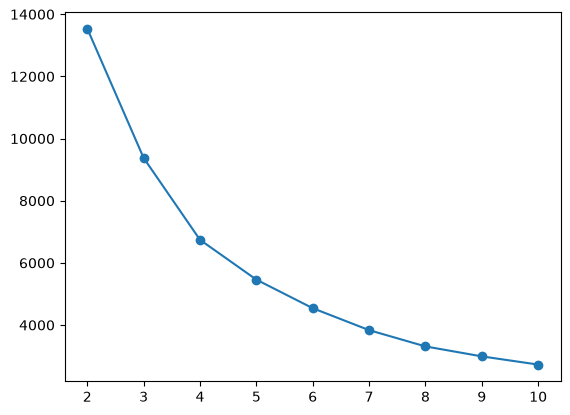

<Figure size 640x480 with 0 Axes>

In [130]:
plt.plot(
    range(2,11),
    inertia,
    marker = 'o'
         )
plt.show
plt.savefig(r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks6\elbow_curve.png")

In [135]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2,11):

    labels = KMeans(
        random_state=42,
        n_init= 10,
        n_clusters = k

    ).fit_predict(x_cluster)


    scores.append(
        silhouette_score(
            x_cluster,
            labels
        )
    )

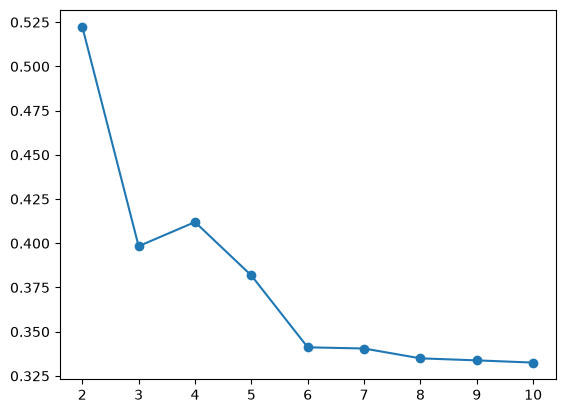

In [136]:
plt.plot(
    range(2,11),
    scores,
    marker = 'o'
         )
plt.show
plt.savefig(r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks6\silhouette_curve.png")

# Selecting K value 

The highest Silhoutte Score was observed at k=2, indicating the strongest mathematical seperation between clusters 

However a two cluster solution provides limited operational insight

k=4 was selected because it still maintains reasonable cluster quality while producing a richer set of interpretable infrastructure operating states, including low traffic , normal operation elevated demand and critical pressure conditions

In [145]:
clusters = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)
cluster_labels = clusters.fit_predict(x_cluster)




In [ ]:
df_cluster = scaling_log_ml[cluster_features].copy()
df_cluster['clusters'] = cluster_labels

In [147]:
cluster_summary = (
    df_cluster.groupby('clusters')
    .mean()
    .round(2)
)

cluster_summary

,active_users,requests_per_min,orders_per_min,cpu_utilization,memory_utilization,network_mbps,disk_utilization,response_time_ms,current_capacity_rpm,capacity_headroom,Utilization Pressure
clusters,,,,,,,,,,,
0,620.40,775.48,11.50,55.62,49.40,256.11,48.56,104.68,2303.61,1528.13,51.19
1,2309.84,2886.84,63.23,97.00,92.27,951.72,72.09,160.09,2513.20,-373.64,87.12
2,1191.55,1490.58,27.60,87.87,66.44,491.36,56.57,133.24,2404.88,914.30,70.30
3,4661.32,5824.55,158.91,97.00,95.00,1926.76,95.00,198.64,2653.85,-3170.71,95.67


### K-Means Cluster Interpretation

Cluster 0 - Low Traffic Steady state

Represents periods of low demand characterized by fewer active users. lower request volume and relatively low infrastructure utilization.

cluster 2 - Moderate Pressure Zone

Represents increasing workload conditions where demand is growing and infrastructure utilization begins to rise

cluster 1 - High Traffic/ Pre-Scale State

Represents periods of sustained high demand where resourse utilization is approaching operational limits and scaling actions may soon be required 

cluster 3 - Critical Pressure Zone

Represents the highest demand conditions observed in the dataset this cluster exhibits in the dataset. This cluster exhibits the largest user population, highest request volume and near-saturated infra utilization, making it the most likely candidate for proactive scaling interventions.

In [148]:
df_cluster['clusters'].value_counts()

clusters
0    1165
2    1005
1     788
3      65
Name: count, dtype: int64

## Hirarchical Clustering 

Hierarchical clustering was applied using the same operational feature set used for K-Means

Unlike K-Means, hirarchical clustering does not require a predefined cluster count and provodes a visual representation of how observations merge into larger groups.

In [149]:
from scipy.cluster.hierarchy import (
    linkage,dendrogram
)

linked = linkage(
    x_cluster,
    method = 'ward'
)

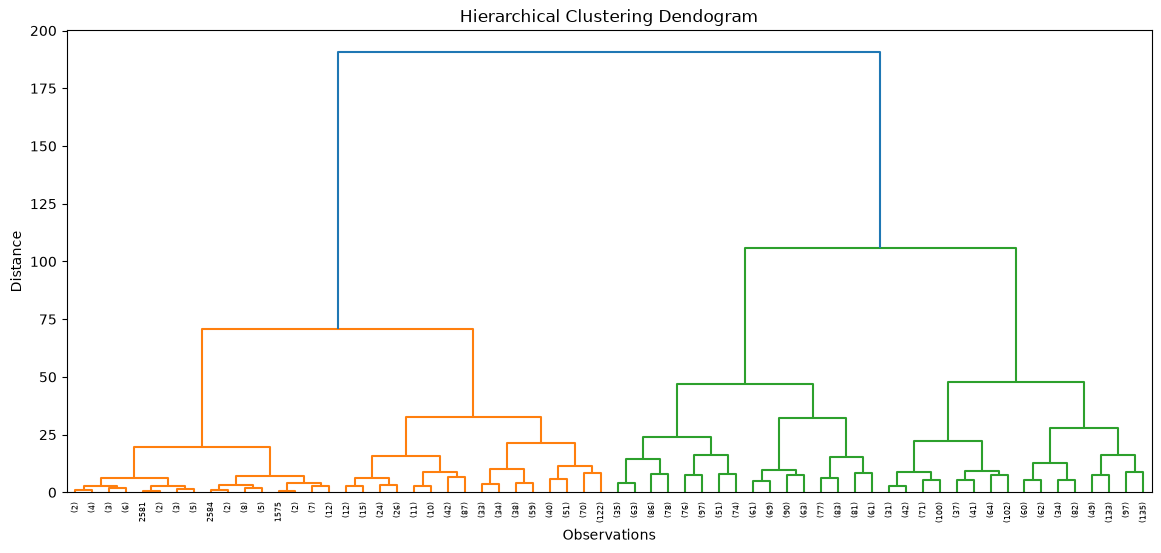

In [151]:
plt.figure(figsize=(14,6))

dendrogram(
    linked,
    truncate_mode='level',
    p = 5
)

plt.title(
    "Hierarchical Clustering Dendogram"
)

plt.xlabel("Observations")
plt.ylabel("Distance")

plt.savefig(r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks6\dendrogram.png",bbox_inches='tight')

plt.show()


The dendogram indicates the presence of two major infrastructure operating groups, as evidenced by large merge occuring at approximatly distance 188

This observation is consistant with the silhoutte analysis, which achived its highest value for k=2

However, both major groups conatain meaningful internal structure, with additional branching occuring at lower linkage distances

For operational analysis, a four- cluster K-Means solution was preferred

In [156]:
#DB Scan 

from sklearn.cluster import DBSCAN

eps_value = [ 0.3,0.5,0.7,0.9,1.1]
min_samples_values = [ 5,10,15]

for eps in eps_value:
    for min_samples in min_samples_values:
        db= DBSCAN(
            eps=eps,
            min_samples= min_samples
        )

        labels = db.fit_predict(
            x_cluster
        )
       
        n_clusters = len(
            set(labels))-(1 if -1 in labels else 0)

        noise_points = (labels == -1 ).sum()

        print(
            f"eps={eps},"f"min_samples={min_samples},"f"clusters={n_clusters},"f"noise={noise_points}"
        )



eps=0.3,min_samples=5,clusters=68,noise=1076
eps=0.3,min_samples=10,clusters=35,noise=2298
eps=0.3,min_samples=15,clusters=5,noise=2897
eps=0.5,min_samples=5,clusters=10,noise=102
eps=0.5,min_samples=10,clusters=8,noise=149
eps=0.5,min_samples=15,clusters=9,noise=201
eps=0.7,min_samples=5,clusters=3,noise=17
eps=0.7,min_samples=10,clusters=3,noise=55
eps=0.7,min_samples=15,clusters=1,noise=83
eps=0.9,min_samples=5,clusters=3,noise=2
eps=0.9,min_samples=10,clusters=3,noise=18
eps=0.9,min_samples=15,clusters=3,noise=36
eps=1.1,min_samples=5,clusters=1,noise=0
eps=1.1,min_samples=10,clusters=3,noise=1
eps=1.1,min_samples=15,clusters=2,noise=30


Several DBSCAN parameter combinations were evaluated.

Very small eps values produced excessive noise points, while very large eps values collapsed the dataset into a small number of overlay broad clusters

The configurations eps=0.9 and min_samples=10 produced three meaningful clusters and only 18 noise observations, providing a balance between cluster formation and anomaly identification.

This configuration was selected for further interpretation.

In [157]:
dbscan = DBSCAN(
    eps = 0.9,
    min_samples=10
)

db_labels = dbscan.fit_predict(
    x_cluster
)

df_cluster['dbscan_cluster'] = db_labels
pd.Series(db_labels).value_counts()

 0    2958
 1      33
-1      18
 2      14
Name: count, dtype: int64

In [158]:
df_cluster.groupby(
    'dbscan_cluster'
).mean().round(2)

,active_users,requests_per_min,orders_per_min,cpu_utilization,memory_utilization,network_mbps,disk_utilization,response_time_ms,current_capacity_rpm,capacity_headroom,Utilization Pressure,clusters
dbscan_cluster,,,,,,,,,,,,
-1,4733.50,5919.89,161.50,93.64,93.19,1952.66,92.16,198.51,2477.78,-3442.11,93.00,2.83
0,1265.57,1582.20,30.79,77.62,66.62,521.77,57.56,129.17,2393.98,811.79,67.27,0.95
1,4134.45,5168.91,140.64,97.00,95.00,1712.64,94.98,191.32,2669.70,-2499.21,95.66,3.00
2,5586.14,6972.50,190.57,97.00,95.00,2308.95,96.00,210.64,2814.29,-4158.21,96.00,3.00


## DBSCAN Results 

DBSCAN was evaluated using multiple combinations of eps and min_samples parameters.

The final configuration ( eps =0.9, min_samples = 10) identified:

- 3 clusters
- 18 noise observations

Cluster distribution:

- Cluster 0 : 2958 observations
- Cluster 1 : 33 observations
- Cluster 2 : 14 observations
- Noise : 18 observations

Unlike K-Means, DBSCAN identified one dominant operating state containing the majority of observations.

Cluster 0 represents the normal operating state of the platform, characterised by moderate demand levels and typical infrastructure utilization.

Clusters 1 and 2 represent increasingly demanding workload conditions, with significatly higher request volumes, active user populations and infrastructure utilization,

The 18 noise observations were not assigned to any cluster. These observations exhibit high workload characteristic and likely represent rare operational conditions, unsual traffic behaviour or extreme demand scenarios.

Rather than aggressively tuning DBSCAN to eliminate noise, these observations were retained and interpreted as valuable indicators of uncommon infrastructure states 

## Compare the three Clustering Approaches 

### K-Means

K-Means produced four balanced and operationally meaningful clusters.
The Clusters aligned well with recognizable infrastructure operating states:

- Low Traffic Steady State
- Moderate Pressure State 
- High Traffic State 
- Critical Pressure Zone

The resulting segmentation was easy to interpret and directly applicable to monitoring and scaling decisions

### Hirarchical Clustering

Hirarchical clustering revealed two major infrastructure operating regimes together with meaningful sub-structure within each regime

The dendogram supported the existence of natural grouping pattrens in the data and provided additional evidence that infrastructure behaviour is not random 

while useful for understanding relationships between observations, hirarchical clustering is less practical for ongoing operational classification than K-Means.

### DBSCAN

DBSCAN succesfully identified one dominant operational state together with several rare workload states and 18 unusual observation

Its Primary strength is anomaly detection rather than balanced operational segmentation.

The identified noise observations may represent rare demand surges, unusual workload conditions or transitional states between operating modes 

# Why Best Matches Operational Reality ?

## Recommended Clustering Approach 

K-Means best matches the operational reality of this dataset.

While Hirarchical Clustering confirms the presence of meaningful natural structure and DBSCAN highlights unusual worklaod conditions, K-means provides the clearest and most actionable representation of infrastructure behaviour 

The four K-Means clusters correspond natuarlly to different workload levels and infrastructure pressure states, making them suitable for operational monitoring , capacity planning and proactive scaling decisions.

Therefore, K-Means is the preferred clustering approach for representing infrastructure operating states within NimbusCart's environment

# Task 7 : Reduce Dimensions and Visualize Results 

## Objective

The objective of this task is to reduce the high-dimensional infrastructure feature set into a two-dimensional representation using PCA and visualize the clustering results

Additional visualization are included to communicate demand patterns, model nehaviour and infrastructure state segmentations


In [159]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=2
)

pca_result = pca.fit_transform(
    x_cluster
)

In [161]:
df_pca = pd.DataFrame(
    pca_result,
    columns=[
        'PC1',
        'PC2'
    ]
)

df_pca['cluster'] = df_cluster['clusters']

In [166]:
retained_info= pca.explained_variance_ratio_.sum()
print(f"The first two Principal components retained {(retained_info*100)} % of the total variance, indicating that the majority of the operational behaviour can be represented within a two dimensional space")

The first two Principal components retained 92.96479288455062 % of the total variance, indicating that the majority of the operational behaviour can be represented within a two dimensional space


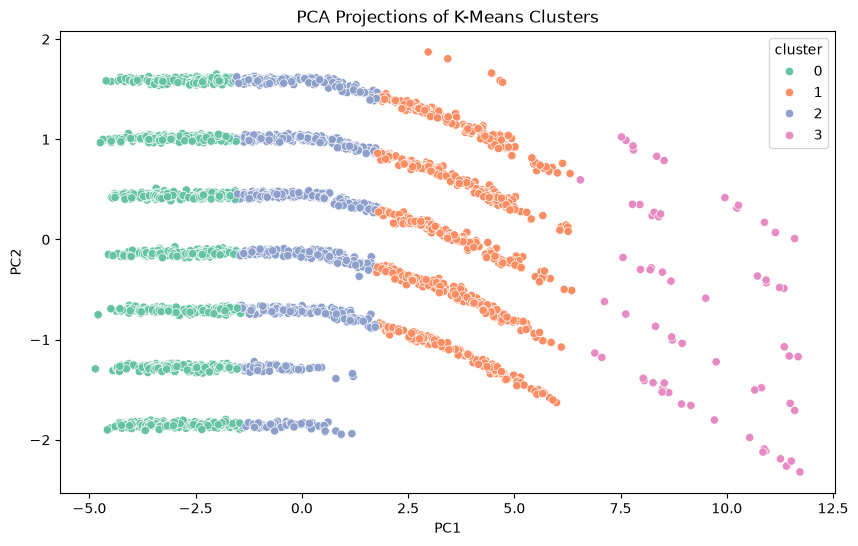

In [167]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data = df_pca,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette = 'Set2'
)

plt.title(
    "PCA Projections of K-Means Clusters"
)

plt.savefig(r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks7\pca_clusters.png",bbox_inches='tight')

plt.show()

The PCA projection demonstrates visible seperation among the K-Means clusters.

Low-demand and high-pressure operating states occupy different regions of the PCA space , supporting the validity of the clustering solution.

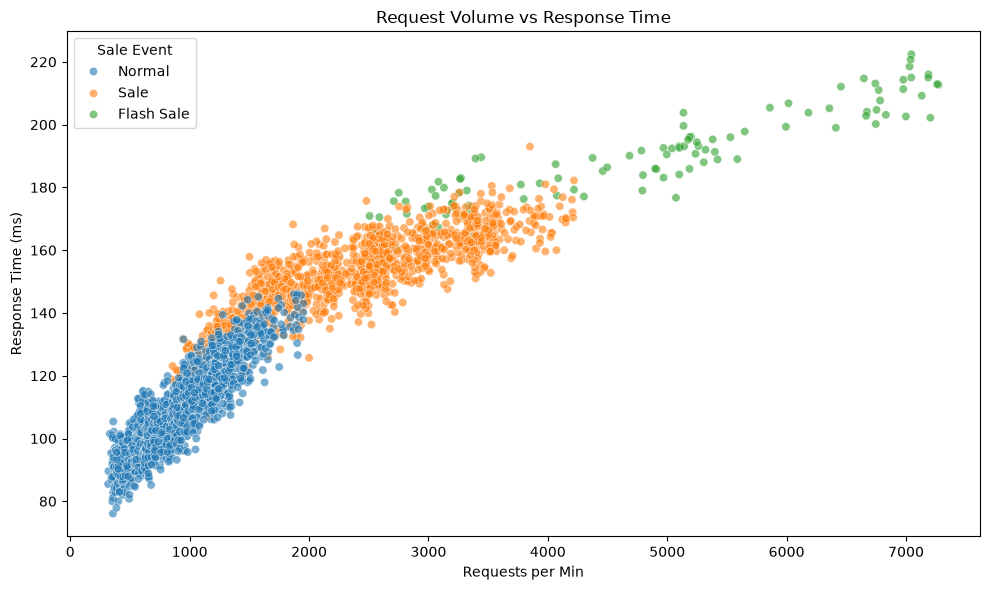

In [168]:
plt.figure(figsize=(10,6))
sns.scatterplot(
    data=scaling_log,
    x='requests_per_min',
    y='response_time_ms',
    hue='sale_event',
    alpha=0.6
)

plt.title('Request Volume vs Response Time')
plt.xlabel("Requests per Min")
plt.ylabel('Response Time (ms)')
plt.legend(title='Sale Event')

plt.tight_layout()
plt.savefig(r"D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks7\requests_vs_response_time.png",bbox_inches='tight')

plt.show()

Response time generally incraeses as request volume grows , suggesting that higher workload places increasing pressure on the infrastructure 

The highest request volumes and response times are concentrated around high-demand operating periods, indicating that response latency can serve as an additional indicator of infrastructure stress

In [169]:
rf_cls.feature_importances_

array([0.09868255, 0.09718766, 0.07176608, 0.00954188, 0.03159655,
       0.12005741, 0.04630753, 0.01873123, 0.03228465, 0.00601879,
       0.00181928, 0.000662  , 0.00244564, 0.00048967, 0.00109673,
       0.00128947, 0.31546507, 0.00628063, 0.05170937, 0.08656781])

In [174]:
feature_importance = pd.DataFrame(
    {
        'Feature': X_train_cls.columns,
        'Importance': rf.feature_importances_
    }
)

feature_importances = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importances.head(10)


,Feature,Importance
1,requests_per_min,0.518968
19,requests_per_cpu,0.270278
5,network_mbps,0.115383
0,active_users,0.058484
2,orders_per_min,0.010452
18,Utilization Pressure,0.009940
6,disk_utilization,0.006581
16,capacity_headroom,0.004149
9,hour_of_day,0.001688
4,memory_utilization,0.001446


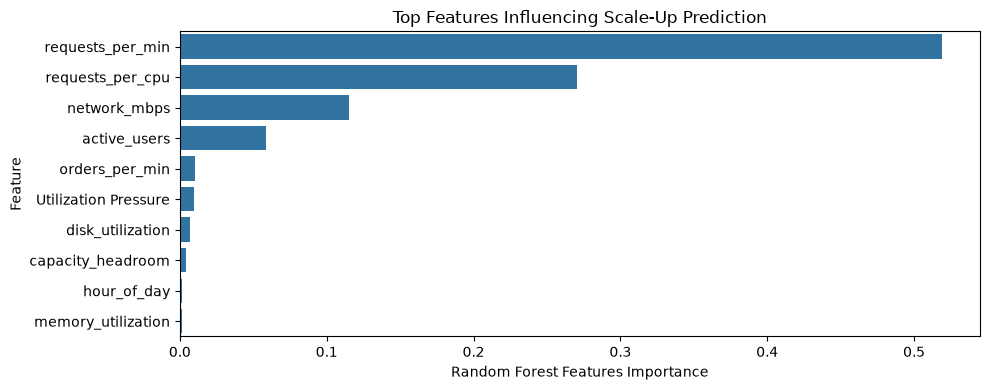

In [175]:
plt.figure(figsize=(10,4))

sns.barplot(
  data=feature_importances.head(10),
  x='Importance',
  y='Feature'
)

plt.title(
    'Top Features Influencing Scale-Up Prediction'
)
plt.xlabel(
    'Random Forest Features Importance'
)

plt.ylabel(
    'Feature'
)

plt.tight_layout()

plt.savefig(
    r'D:\Projects\ecommerce-infrastructure-scaling\outputs\tasks7\random_forest_feature_importance.png',bbox_inches ='tight'
)

plt.show()

### Random Forest Feature Importance 

The Random Forest model relied primarily on current workload characteristics when predicting proactive scale-up requirements.

Requests Per Min was the dominant predictor, followed by Requests Per CPUc, Network Throughput and Active Users.

This suggests that scale-up decisions in the dataset are driven primarily by current request demand and workload intensity.

Some engineered features, including Utilization Pressure and Capacity Headroom, demonstarted useful relationships with the target during exploratory analysis but recieved lower random Forest Feature importance. This indicated that much of the info represented by these engineered features may already be captured by stronger workload variabled such as Requests Per Minute and Requests Per CPU, Network Throughput and Active Users.

This suggests that scale-up decisions in the dataset are driven primarily by current request demand and workload intensity 

Some engineered features including Utilization pressure and capacity Headroom , demonstarted useful relationships with the target during exploartory analysis but recievd lower Random Forest feature importance.This indicates that much of the information represented by these engineered features may alreday be captured by stronger workload variables such as Request per min and requests per CPU

In [ ]:
# Task 8: Proactive Capacity Recommendation

In [176]:
event_summary = (
    scaling_log
    .groupby('sale_event')
    .agg({
        'active_users':'mean',
        'requests_per_min':'mean',
        'orders_per_min': 'mean',
        'cpu_utilization':'mean',
        'memory_utilization':'mean',
        'network_mbps':'mean',
        'response_time_ms':'mean',
         'current_capacity_rpm':'mean'
    }).round(2)
)

event_summary

,active_users,requests_per_min,orders_per_min,cpu_utilization,memory_utilization,network_mbps,response_time_ms,current_capacity_rpm
sale_event,,,,,,,,
Flash Sale,3833.46,4789.70,130.28,97.00,94.88,1582.16,189.28,2675.93
Normal,757.73,947.12,13.69,63.99,53.52,312.79,110.31,2299.24
Sale,1824.25,2281.01,49.22,93.14,81.26,751.69,150.05,2496.10


## Demand and Infrastructure Patterns 

Demand increases progressively from Normal operations through Sale and Flash Sale periods

Flash Sale periods show the highest active-user and request volumes and are accompained by increased infrastructure utilization and response times.

This indicates that promotional events create materially different operating conditions compared with normal platform activity

# Demand Forecasting Performnace 

The Linear Regression model achived:

MAE: 64.8004754274893
RMSE: 191.50404265671494
MAPE: 0.022980205356006575

The MAE means that the short-term demand forecast differs from actual demand by approximatly 64 requests per min on average 

the higher RMSE reflects larger prediction errors during some extreme demand periods.

MAPE was also reviewed to provide a percentage-based interpretations of forecasting error

Error analysis showed that forecasting performnace was the strongest during normal operating periods and deteriorated during Flash sale events , where sudden demand chnages were most difficult to predict 


## Proactive Scale-Up Classification

Both DT and Random forest demonstarted strong classification performance.

RF provided slightly better results across Accuracy , Precision, recall and F1 score

More importantly , RF reduced False Negatives from 18 to 15, In operational terms these represent situations where infrastructure scaling was required but the model failed to recommend it.

Because missing a required scale-up presents greater availability risk than performing an unnecessary scale-up, random Forest is recommended as the preferred classifier for production consideration.

## Infrastructure Operating States

Unsupervised learning identified multiple infrastructure operating states

K-means provided the most actionable segmentations , producing four states representing progressively increasing workload and infrastructure pressure.

The clusters ranged from low-traffic steady-state operation through elevated demand and ultimately critical-Pressure conditions 

Hierarchical clustering supported the presence of broader natural operating regimes , while DBSCAN identified one dominant operating state together with rare high-demand conditions and 18 unusual observations

These states could be used by the SRE team as contextual indicators alongside forecasting and scale-up predictions

## Capacity Readiness Assessment

The analysis indicates that the current infrastructure is generally capable of supporting Normal operating conditions.

However, the same conclusion cannot be extended to extreme high-demand periods

Observed demand reaches levels substantially above current provisioned capacity during peak conditions and negative Capacity headroom values occur within the dataset. Clustering analysis also identifies distinct high-pressure and critical operating states 

Therefore current capacity should not be assumed to safely handle all upcoming Sale or Flash Sale conditions without proactive scaling

### Monitoring Recommendation

- Monitor demand forecasts, capacity headroom and infrastructure utilization together during high-traffic periods,
- Use the 15-min demand forecast as an early-warning signal rather than waiting signal rather than waiting for resources to reach critical utilization.
- Increase monitoring attension during sale and Flash sale periods , where the largest demand spikes were observed 
-Trigger proactive investigation when the classifier recommends scale-up or the environment enters a high-presuure cluster

### Alerting Recommendations 

Alerts should combine multiple signals rather than rely on a single metric:

- Forecast demand approaching available capacity 
- capacity Headroom approaching zero or becoming negative 
- High Utilization Presure
- random Forest predicting scale-up required 
Infra enetring high or critical pressure cluster

Multiple simultaneous signals should be treated as stronger evidence for proactive scaling

### Model Limitations 

- Model are based on historical patterns and may not capture new or unexpected traffic behaviour
- Forecasting errors were higher during Flash sale periods 
-Clusters represent statistical patterns rather than fixed operational thresholds
-Infra and user behaviour may change over time requiring model monitoring and retraining.
-Predictions should support SRE decisions , not automatically replace human judgement

Overall, the models provide useful early-warning signals for capacity planning, but real-time telemetry and SRE judgement should remain part of the final scaling decision